**Predicción del rendimiento del trigo en Argentina**

Este notebook presenta el análisis exploratorio de los datos y el desarrollo de dos modelos de regresión (regresión lineal y árbol de decisión) para estimar el rendimiento del trigo, en kg/ha, de un departamento en una campaña, al finalizar la siembra.

**Origen de los datos**

Los datos provienen del conjunto oficial *Trigo: siembra, cosecha, producción y rendimiento* de la Secretaría de Agricultura, Ganadería y Pesca (https://datos.magyp.gob.ar/dataset/trigo-siembra-cosecha-produccion-rendimiento). Cada fila representa un departamento en una campaña agrícola. El archivo original completo (25.231 filas y 11 columnas, campañas 1927 a 2025) se conserva sin modificaciones en `data/raw/`. La descripción detallada está en `docs/descripcion_dataset.md`.

**Período de estudio**

Se trabaja con las campañas 2000 a 2025 (6.053 filas), por la calidad del objetivo, la cobertura estable de departamentos y la menor confiabilidad de los datos antiguos.

In [1]:
import pandas as pd

df = pd.read_csv(
    "../data/raw/trigo-serie-1927-2025.csv",
    dtype={"provincia_id": str, "departamento_id": str},
    encoding="latin-1",
)

periodo = df[(df["anio"] >= 2000) & (df["anio"] <= 2025)].copy()
periodo["rendimiento_kgxha"].describe()

count    6053.000000
mean     2607.045267
std      1220.259419
min         0.000000
25%      1600.000000
50%      2500.000000
75%      3599.000000
max      7186.000000
Name: rendimiento_kgxha, dtype: float64

In [2]:
ceros = periodo[periodo["rendimiento_kgxha"] == 0]
print(len(ceros))
ceros.head(10)

44


,cultivo,anio,campania,provincia,provincia_id,departamento,departamento_id,superficie_sembrada_ha,superficie_cosechada_ha,produccion_tm,rendimiento_kgxha
20385,trigo,2005,2005/2006,Santiago del Estero,86,Alberdi,86014,2000,0.0,0.0,0.0
20388,trigo,2005,2005/2006,Santiago del Estero,86,Choya,86063,200,0.0,0.0,0.0
20389,trigo,2005,2005/2006,Santiago del Estero,86,Copo,86056,1500,0.0,0.0,0.0
20390,trigo,2005,2005/2006,Santiago del Estero,86,Figueroa,86070,100,0.0,0.0,0.0
20392,trigo,2005,2005/2006,Santiago del Estero,86,Guasayán,86084,500,0.0,0.0,0.0
20598,trigo,2006,2006/2007,San Luis,74,Chacabuco,74028,380,0.0,0.0,0.0
20600,trigo,2006,2006/2007,San Luis,74,Gobernador Dupuy,74042,600,0.0,0.0,0.0
20601,trigo,2006,2006/2007,San Luis,74,Juan Martín de Pueyrredón,74056,150,0.0,0.0,0.0
20625,trigo,2006,2006/2007,Santiago del Estero,86,Guasayán,86084,200,0.0,0.0,0.0
20636,trigo,2006,2006/2007,Santiago del Estero,86,Sarmiento,86182,100,0.0,0.0,0.0


In [3]:
print(ceros["provincia"].value_counts())

calc = periodo["produccion_tm"] * 1000 / periodo["superficie_cosechada_ha"]
print(((periodo["rendimiento_kgxha"] - calc).abs() > 0.05 * calc).sum())

provincia
Santiago del Estero    25
Tucumán                 6
San Luis                3
Chaco                   3
Córdoba                 2
Buenos Aires            2
Jujuy                   2
La Pampa                1
Name: count, dtype: int64
0


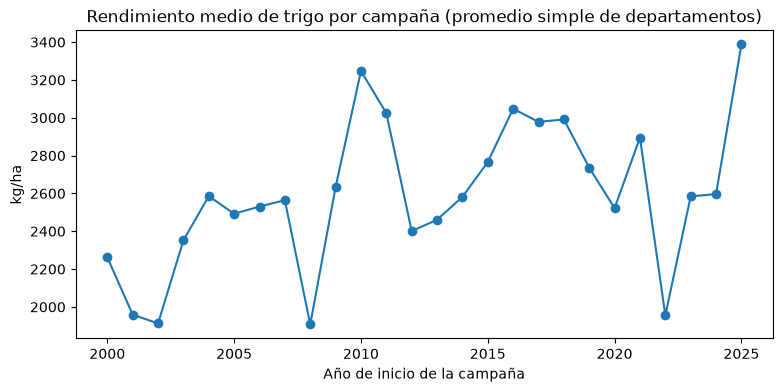

In [4]:
import matplotlib.pyplot as plt

por_anio = periodo.groupby("anio")["rendimiento_kgxha"].mean()
por_anio.plot(marker="o", figsize=(9, 4))
plt.title("Rendimiento medio de trigo por campaña (promedio simple de departamentos)")
plt.ylabel("kg/ha")
plt.xlabel("Año de inicio de la campaña")
plt.show()

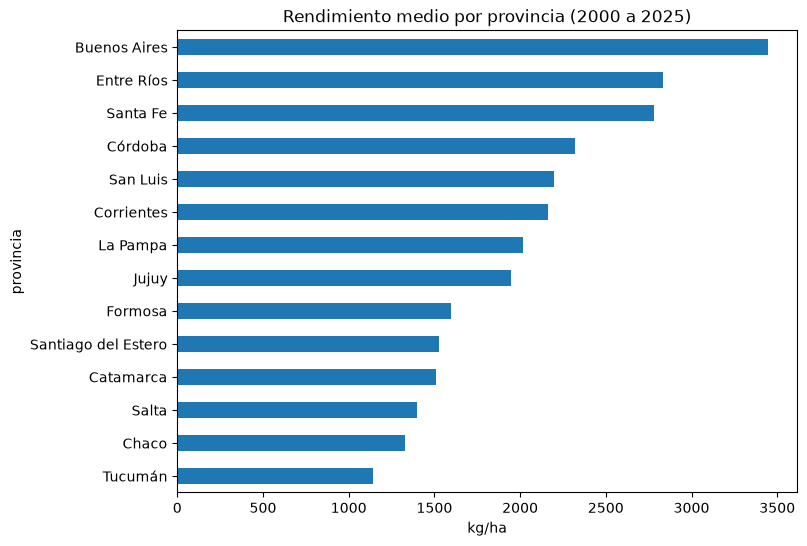

                       mean  count
provincia                         
Tucumán              1142.0    229
Chaco                1328.0    446
Salta                1398.0    281
Catamarca            1508.0     51
Santiago del Estero  1526.0    390
Formosa              1594.0     33
Jujuy                1944.0    118
La Pampa             2019.0    380
Corrientes           2163.0     61
San Luis             2200.0    140
Córdoba              2322.0    515
Santa Fe             2780.0    474
Entre Ríos           2834.0    412
Buenos Aires         3445.0   2523


In [5]:
por_prov = periodo.groupby("provincia")["rendimiento_kgxha"].agg(["mean", "count"]).sort_values("mean")
por_prov["mean"].plot(kind="barh", figsize=(8, 6))
plt.title("Rendimiento medio por provincia (2000 a 2025)")
plt.xlabel("kg/ha")
plt.show()
print(por_prov.round(0))

                        superficie_sembrada_ha  rendimiento_kgxha
superficie_sembrada_ha                    1.00               0.11
rendimiento_kgxha                         0.11               1.00


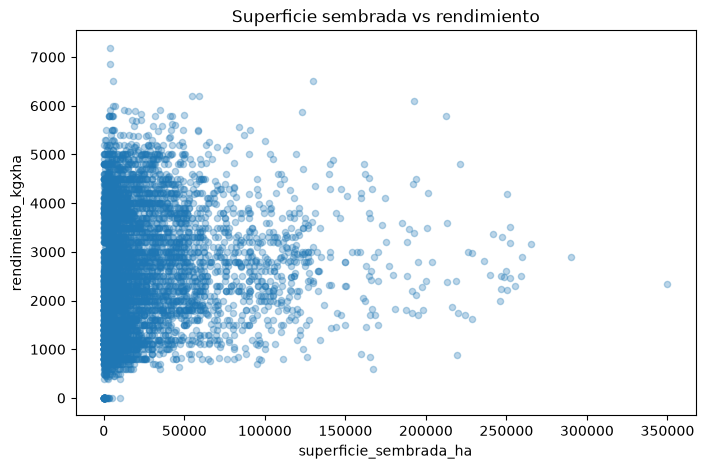

In [6]:
print(periodo[["superficie_sembrada_ha", "rendimiento_kgxha"]].corr().round(2))

periodo.plot.scatter(x="superficie_sembrada_ha", y="rendimiento_kgxha", alpha=0.3, figsize=(8, 5))
plt.title("Superficie sembrada vs rendimiento")
plt.show()

In [7]:
previo = periodo[["departamento_id", "anio", "rendimiento_kgxha"]].copy()
previo["anio"] = previo["anio"] + 1
previo = previo.rename(columns={"rendimiento_kgxha": "rend_anterior"})

con_prev = periodo.merge(previo, on=["departamento_id", "anio"], how="left")
print(con_prev["rend_anterior"].notna().sum())
print(con_prev[["rendimiento_kgxha", "rend_anterior"]].corr().round(2))

5637
                   rendimiento_kgxha  rend_anterior
rendimiento_kgxha               1.00           0.71
rend_anterior                   0.71           1.00


In [8]:
base = periodo[["departamento_id", "anio", "rendimiento_kgxha"]]
datos = periodo.copy()
for k in (1, 2, 3):
    lag = base.copy()
    lag["anio"] = lag["anio"] + k
    lag = lag.rename(columns={"rendimiento_kgxha": f"rend_{k}"})
    datos = datos.merge(lag, on=["departamento_id", "anio"], how="left")

datos["rend_anterior"] = datos["rend_1"]
datos["rend_prom3"] = datos[["rend_1", "rend_2", "rend_3"]].mean(axis=1)

print(datos["rend_prom3"].notna().sum())
print(datos[["rendimiento_kgxha", "rend_anterior", "rend_prom3"]].corr().round(2))

5717
                   rendimiento_kgxha  rend_anterior  rend_prom3
rendimiento_kgxha               1.00           0.71        0.75
rend_anterior                   0.71           1.00        0.90
rend_prom3                      0.75           0.90        1.00


**Análisis exploratorio: hallazgos**

- **Rendimiento:** en 2000 a 2025 el promedio es de unos 2.600 kg/ha (mediana 2.500), con mucha dispersión (desvío de unos 1.200 kg/ha, entre 0 y 7.186).
- **Rendimiento igual a cero:** 44 filas (25 en Santiago del Estero) tienen superficie sembrada pero producción nula. Se conservan, porque el modelo predice al finalizar la siembra y en ese momento todavía no se sabe si el lote se cosechará. No hay rendimientos inconsistentes ni registros repetidos en el período.
- **Evolución en el tiempo:** el rendimiento medio pasa de unos 2.200 kg/ha en 2000 a unos 3.400 en 2025, con caídas marcadas en 2001 y 2002, 2008, 2012 y 2022. Los datos no permiten afirmar la causa de cada caída.
- **Provincias:** solo 14 de las 22 provincias del archivo tienen registros en el período. Buenos Aires concentra el 42 % de las filas y tiene el mayor rendimiento medio (unos 3.445 kg/ha), mientras que Tucumán, Chaco y Salta están entre 1.100 y 1.400 kg/ha. La ubicación parece aportar información, aunque esto no explica por qué las provincias rinden distinto.
- **Superficie sembrada:** su correlación con el rendimiento es débil (0,11), por lo que por sí sola aporta poca información.
- **Rendimiento de campañas anteriores:** el rendimiento de la campaña anterior del mismo departamento correlaciona 0,71 con el rendimiento actual, y el promedio de las tres campañas anteriores, 0,75. Por eso se incorporan como variables derivadas. Es una asociación y no implica causalidad.

**Preparación de los datos para el modelo**

*Variables predictoras*

- `provincia` y `departamento_id`: ubicación del departamento.
- `anio`: año de inicio de la campaña.
- `superficie_sembrada_ha`: superficie sembrada.
- `rend_anterior`: rendimiento del mismo departamento en la campaña anterior.
- `rend_prom3`: promedio del rendimiento del mismo departamento en las tres campañas anteriores (o en las que existan).

Las variables derivadas usan únicamente campañas previas a la que se predice, porque son datos que ya se conocen al finalizar la siembra. No se usan `produccion_tm` ni `superficie_cosechada_ha`, ya que permiten calcular el rendimiento y no están disponibles al momento de la predicción (fuga de información).

*Filas utilizadas*

Se descartan las filas sin campaña anterior en el período (416 de 6.053), porque no tienen historia para calcular las variables derivadas. Quedan 5.637 filas para el modelo.

*Separación entre entrenamiento y prueba*

Se separa por fecha y no al azar, porque el objetivo es predecir campañas futuras a partir de campañas pasadas:

- **Entrenamiento:** campañas 2000 a 2019 (4.128 filas).
- **Prueba:** campañas 2020 a 2025 (1.509 filas).

La separación se hace antes de cualquier transformación, para que la prueba no influya en el entrenamiento.

In [9]:
modelo = datos.dropna(subset=["rend_anterior"]).copy()
entrenamiento = modelo[modelo["anio"] <= 2019]
prueba = modelo[modelo["anio"] >= 2020]
print(len(modelo), len(entrenamiento), len(prueba))

5637 4128 1509


**Métricas y referencias sencillas**

Para evaluar los modelos se usan tres métricas de regresión, calculadas sobre la prueba:

- **MAE:** error absoluto promedio, en kg/ha.
- **RMSE:** similar al MAE, pero penaliza más los errores grandes.
- **R²:** proporción de la variación del rendimiento que explica el modelo (0 equivale a no mejorar al promedio).

Antes de entrenar los modelos se calculan dos referencias sencillas, contra las que se comparan sus resultados:

- **Promedio de entrenamiento:** predice siempre el rendimiento promedio de las campañas 2000 a 2019.
- **Campaña anterior:** predice que cada departamento repetirá el rendimiento de la campaña anterior.

Un modelo solo aporta algo si supera a estas reglas simples.

In [10]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_train = entrenamiento["rendimiento_kgxha"]
y_test = prueba["rendimiento_kgxha"]

def metricas(y_real, y_pred):
    return {
        "MAE": round(mean_absolute_error(y_real, y_pred)),
        "RMSE": round(np.sqrt(mean_squared_error(y_real, y_pred))),
        "R2": round(r2_score(y_real, y_pred), 2),
    }

print("Promedio de entrenamiento:", metricas(y_test, np.full(len(y_test), y_train.mean())))
print("Campaña anterior:", metricas(y_test, prueba["rend_anterior"]))

Promedio de entrenamiento: {'MAE': 1173, 'RMSE': 1366, 'R2': -0.0}
Campaña anterior: {'MAE': 757, 'RMSE': 1092, 'R2': 0.36}


**Modelos**

Se entrenan dos modelos de regresión de scikit-learn, con las mismas variables predictoras:

- **Regresión lineal:** estima el rendimiento como una combinación de las variables. Las variables de texto (provincia y departamento) se convierten en columnas de 0 y 1 (codificación one-hot).
- **Árbol de decisión para regresión:** divide los datos en grupos mediante preguntas sobre las variables y predice el promedio de cada grupo. Sin límites tiende a memorizar el entrenamiento, por lo que se ajusta su profundidad.

No se escalan las variables numéricas: ni la regresión lineal ni el árbol cambian sus predicciones si las variables se reescalan, por lo que no aportaría nada. Los códigos de departamento se usan en lugar de los nombres, porque un mismo nombre puede repetirse en distintas provincias.

En una primera versión, ambos modelos se entrenan con 2000 a 2019 y se evalúan con 2020 a 2025.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

columnas = ["provincia", "departamento_id", "anio",
            "superficie_sembrada_ha", "rend_anterior", "rend_prom3"]

def preparar():
    return ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore"), ["provincia", "departamento_id"])],
        remainder="passthrough",
    )

lineal = Pipeline([("prep", preparar()), ("modelo", LinearRegression())])
arbol = Pipeline([("prep", preparar()), ("modelo", DecisionTreeRegressor(random_state=42))])

for nombre, m in [("Regresión lineal", lineal), ("Árbol de decisión", arbol)]:
    m.fit(entrenamiento[columnas], y_train)
    print(nombre, metricas(y_test, m.predict(prueba[columnas])))

Regresión lineal {'MAE': 682, 'RMSE': 912, 'R2': 0.55}
Árbol de decisión {'MAE': 848, 'RMSE': 1098, 'R2': 0.35}


**Ajuste del árbol de decisión**

El árbol sin límites quedó por debajo de la referencia de la campaña anterior, algo esperable porque tiende a memorizar el entrenamiento. Para ajustar sus hiperparámetros sin usar la prueba (2020 a 2025), se hace una validación dentro del período de entrenamiento: se entrena con 2000 a 2014 y se valida con 2015 a 2019, manteniendo el orden temporal.

Se compararon distintas profundidades máximas (3, 5, 8, 12 y sin límite) y tamaños mínimos de hoja (1, 10 y 30). La mejor profundidad fue 3, y el tamaño mínimo de hoja no modificó el resultado. Como 3 era el valor más bajo probado, se verificaron también las profundidades 2, 3 y 4:

| Profundidad | MAE de validación (kg/ha) |
|---|---|
| 2 | 543 |
| 3 | 534 |
| 4 | 540 |

Se fijó la profundidad en 3, elegida solo con datos de entrenamiento. La regresión lineal no tiene hiperparámetros que ajustar en esta versión.

In [12]:
sub_train = entrenamiento[entrenamiento["anio"] <= 2014]
validacion = entrenamiento[entrenamiento["anio"] >= 2015]

resultados = []
for profundidad in [3, 5, 8, 12, None]:
    for hoja in [1, 10, 30]:
        m = Pipeline([("prep", preparar()),
                      ("modelo", DecisionTreeRegressor(max_depth=profundidad,
                                                       min_samples_leaf=hoja,
                                                       random_state=42))])
        m.fit(sub_train[columnas], sub_train["rendimiento_kgxha"])
        mae = mean_absolute_error(validacion["rendimiento_kgxha"], m.predict(validacion[columnas]))
        resultados.append((profundidad, hoja, round(mae)))

pd.DataFrame(resultados, columns=["profundidad", "hoja_minima", "MAE_validacion"]).sort_values("MAE_validacion").head(5)

,profundidad,hoja_minima,MAE_validacion
0,3.0,1,534
1,3.0,10,534
2,3.0,30,534
5,5.0,30,599
3,5.0,1,612


In [13]:
resultados = []
for profundidad in [2, 3, 4]:
    m = Pipeline([("prep", preparar()),
                  ("modelo", DecisionTreeRegressor(max_depth=profundidad, random_state=42))])
    m.fit(sub_train[columnas], sub_train["rendimiento_kgxha"])
    mae = mean_absolute_error(validacion["rendimiento_kgxha"], m.predict(validacion[columnas]))
    resultados.append((profundidad, round(mae)))

print(resultados)

[(2, 543), (3, 534), (4, 540)]


In [14]:
arbol_final = Pipeline([("prep", preparar()),
                        ("modelo", DecisionTreeRegressor(max_depth=3, random_state=42))])
arbol_final.fit(entrenamiento[columnas], y_train)

print("Árbol (profundidad 3):", metricas(y_test, arbol_final.predict(prueba[columnas])))
print("Regresión lineal:", metricas(y_test, lineal.predict(prueba[columnas])))
print("Campaña anterior:", metricas(y_test, prueba["rend_anterior"]))

Árbol (profundidad 3): {'MAE': 685, 'RMSE': 906, 'R2': 0.56}
Regresión lineal: {'MAE': 682, 'RMSE': 912, 'R2': 0.55}
Campaña anterior: {'MAE': 757, 'RMSE': 1092, 'R2': 0.36}


**Resultados en la prueba (campañas 2020 a 2025)**

Con el árbol de profundidad 3, entrenado con todo el período de entrenamiento y evaluado una sola vez en la prueba:

| Modelo | MAE (kg/ha) | RMSE (kg/ha) | R² |
|---|---|---|---|
| Referencia: promedio de entrenamiento | 1.173 | 1.366 | 0,00 |
| Referencia: campaña anterior | 757 | 1.092 | 0,36 |
| Regresión lineal | 682 | 912 | 0,55 |
| Árbol de decisión (profundidad 3) | 685 | 906 | 0,56 |

- Los dos modelos superan a las dos referencias. Respecto de repetir la campaña anterior, el MAE baja alrededor de un 10 %.
- La regresión lineal y el árbol quedan prácticamente empatados (3 kg/ha de diferencia en el MAE), por lo que estos resultados no permiten decir que uno sea mejor que el otro.
- El error promedio ronda los 680 kg/ha, y los modelos explican algo más de la mitad de la variación del rendimiento.

In [15]:
resultado = prueba[["anio"]].copy()
resultado["real"] = y_test
resultado["error_lineal"] = lineal.predict(prueba[columnas]) - y_test
resultado["error_arbol"] = arbol_final.predict(prueba[columnas]) - y_test
print(resultado.groupby("anio")[["real", "error_lineal", "error_arbol"]].mean().round(0))

        real  error_lineal  error_arbol
anio                                   
2020  2540.0         372.0        280.0
2021  2928.0        -135.0       -258.0
2022  1958.0         936.0        789.0
2023  2626.0         -71.0        -38.0
2024  2610.0         123.0        -35.0
2025  3405.0        -696.0       -865.0


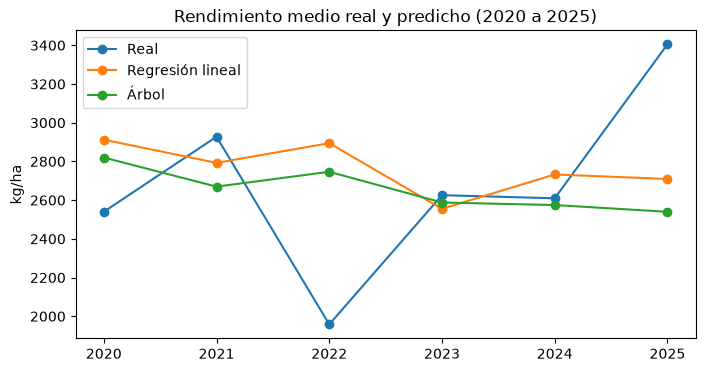

In [16]:
real = resultado.groupby("anio")["real"].mean()
plt.figure(figsize=(8, 4))
plt.plot(real.index, real, marker="o", label="Real")
plt.plot(real.index, real + resultado.groupby("anio")["error_lineal"].mean(), marker="o", label="Regresión lineal")
plt.plot(real.index, real + resultado.groupby("anio")["error_arbol"].mean(), marker="o", label="Árbol")
plt.title("Rendimiento medio real y predicho (2020 a 2025)")
plt.ylabel("kg/ha")
plt.legend()
plt.show()

**Error por año**

Se calculó el error medio de cada modelo en cada campaña de la prueba (predicción menos valor real: positivo si el modelo sobreestima y negativo si subestima) y se comparó el rendimiento real con el predicho.

| Año | Rendimiento real (kg/ha) | Error regresión lineal | Error árbol |
|---|---|---|---|
| 2020 | 2.540 | +372 | +280 |
| 2021 | 2.928 | -135 | -258 |
| 2022 | 1.958 | +936 | +789 |
| 2023 | 2.626 | -71 | -38 |
| 2024 | 2.610 | +123 | -35 |
| 2025 | 3.405 | -696 | -865 |

- En 2023 y 2024 las predicciones quedan cerca del valor real.
- Los mayores errores se dan en 2022, campaña con una caída fuerte del rendimiento, que ambos modelos sobreestiman, y en 2025, el año con mayor rendimiento del período, que ambos subestiman.
- Los dos modelos predicen valores bastante parejos entre años y siguen el nivel general, pero no las oscilaciones bruscas entre una campaña y la siguiente. Esto es esperable porque se apoyan en el rendimiento de campañas anteriores.
- El dataset no incluye variables climáticas, por lo que no es posible determinar a qué se debieron las variaciones de 2022 y 2025. Incorporar esa información podría ser una mejora futura.

**Conclusiones**

*Sobre el problema planteado*

La pregunta del proyecto era si es posible estimar el rendimiento del trigo de un departamento en una campaña, al finalizar la siembra, a partir de su ubicación, la campaña y la superficie sembrada. Con los datos del período 2000 a 2025, los modelos entrenados lograron estimaciones mejores que las de dos reglas sencillas de referencia, aunque con un margen de error considerable.

- La regresión lineal y el árbol de decisión (profundidad 3) tuvieron un MAE de 682 y 685 kg/ha, frente a 757 de repetir la campaña anterior y 1.173 de predecir siempre el promedio. Explican algo más de la mitad de la variación del rendimiento (R² de 0,55 y 0,56).
- La diferencia entre los dos modelos es mínima, por lo que estos resultados no permiten afirmar que uno sea mejor que el otro.
- Los modelos siguen el nivel general del rendimiento, pero no anticipan cambios bruscos de una campaña a la siguiente. En 2022, con una caída fuerte, sobreestimaron el rendimiento, y en 2025, con el valor más alto del período, lo subestimaron.

*Sobre cómo interpretar los resultados*

- Las relaciones observadas entre las variables y el rendimiento son asociaciones y no implican causalidad. Por ejemplo, que el rendimiento de campañas anteriores correlacione con el actual no indica por qué un departamento rinde más que otro.
- No se evaluó el aporte individual de cada variable al modelo, por lo que no se puede afirmar cuál de ellas es la más importante.
- Los resultados corresponden a un único período de prueba de seis campañas, por lo que podrían variar con otro período.

*Limitaciones*

- El dataset no incluye variables climáticas, que probablemente expliquen parte de las variaciones entre campañas. No es posible confirmarlo con estos datos.
- En el período solo hay 14 de las 22 provincias del archivo, y Buenos Aires concentra el 42 % de las filas, por lo que el modelo tiene mucha más información de esa provincia que de las demás.
- Las predicciones corresponden al rendimiento medio de un departamento y no al de un establecimiento particular.
- Se descartaron 416 filas sin campaña anterior, y 44 filas tienen rendimiento cero (se conservaron).

*Posibles mejoras*

Incorporar datos meteorológicos públicos, evaluar el aporte de cada variable y comparar otros períodos de prueba.